# 01 — Ornstein-Uhlenbeck pairs trading (KO / PEP)

Question : l'écart de prix entre Coca-Cola et Pepsi revient-il vers sa moyenne, et à quelle vitesse ?

## Étape 1 — Données
Prix de clôture ajustés, passés en log (un écart en log = un écart en %).

[*********************100%***********************]  2 of 2 completed


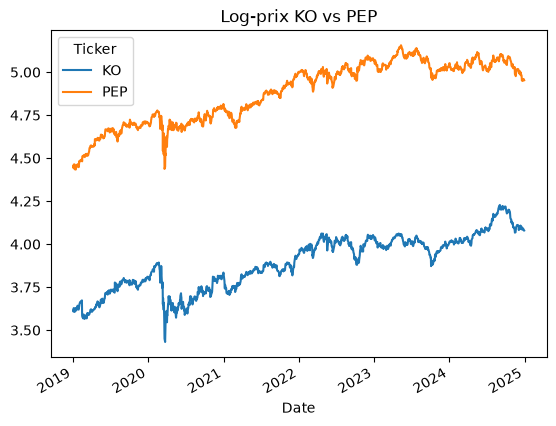

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

px = yf.download(["KO", "PEP"], start="2019-01-01", end="2024-12-31",
                 auto_adjust=True)["Close"].dropna()
logp = np.log(px)

logp.plot(title="Log-prix KO vs PEP")
plt.show()

## Étape 2 — Test de cointégration (Engle-Granger)
p-value < 0,05 → l'écart revient vers sa moyenne.

In [3]:
from statsmodels.tsa.stattools import coint

score, pvalue, _ = coint(logp["KO"], logp["PEP"])
print(f"p-value Engle-Granger : {pvalue:.4f}")

p-value Engle-Granger : 0.3063


**Ma réponse :** pourquoi deux actions qui montent ensemble ne sont pas forcément cointégrées ?

_À écrire ici._

In [2]:
paires = [("KO", "PEP"), ("V", "MA"), ("XOM", "CVX"), ("HD", "LOW"), ("EWA", "EWC")]

for a, b in paires:
    # 1. Télécharger les prix des deux actions
    prix = yf.download([a, b], start="2019-01-01", end="2024-12-31",
                       auto_adjust=True, progress=False)["Close"].dropna()

    # 2. Passer en log
    # À TOI : crée une variable "log_prix" qui contient le log de "prix"
    log_prix = np.log(prix)

    # (regarde comment on a fait "logp" à l'étape 1)


    # 3. Tester la cointégration
    resultat = coint(log_prix[a], log_prix[b])
    # À TOI : appelle coint() sur log_prix[a] et log_prix[b]
    p_value = resultat[1]
    # (regarde l'étape 2), et récupère la p-value

    # 4. Afficher le résultat
    print(f"{a} / {b} : {p_value:.4f}")
    # À TOI : print la paire et sa p-value, par exemple "V / MA : 0.0421"
    

KO / PEP : 0.3063
V / MA : 0.0001
XOM / CVX : 0.0765
HD / LOW : 0.0818
EWA / EWC : 0.0563


## Étape 3 — Hedge ratio
Régression OLS de log(KO) sur log(PEP) → β, puis spread X_t = log(KO) − β·log(PEP).

_À coder._

Hedge ratio β : 0.8562


<Axes: title={'center': 'Spread (log(V) - β * log(MA))'}, xlabel='Date'>

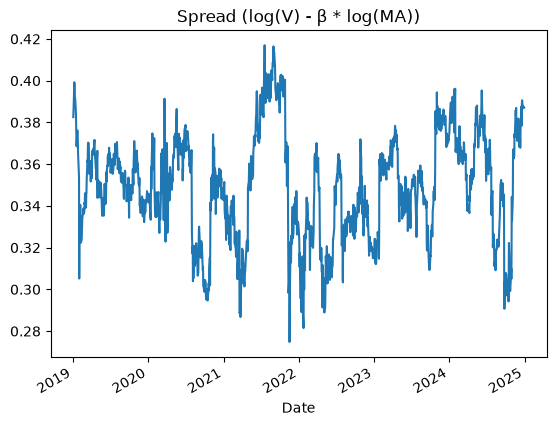

In [1]:
import statsmodels.api as sm

prix = yf.download(["V", "MA"], start="2019-01-01", end="2024-12-31",
                   auto_adjust=True, progress=False)["Close"].dropna()
log_prix = np.log(prix)

# Régression : log(V) expliqué par log(MA)
X = sm.add_constant(log_prix["MA"])
modele = sm.OLS(log_prix["V"], X).fit()
beta = modele.params["MA"]
print(f"Hedge ratio β : {beta:.4f}")

# calcule le spread = log(V) - beta * log(MA)
spread = log_prix["V"] - beta * log_prix["MA"]

# trace le spread avec un titre (comme logp.plot(...) à l'étape 1)
spread.plot(title="Spread (log(V) - β * log(MA))")

## Étape 4 — Estimation OU
Régression de ΔX_t sur X_{t-1} → θ, μ, σ, demi-vie = ln(2)/θ.

_À coder._

In [10]:
# Spread nettoyé
s = spread.dropna()

# ΔX_t = X_t − X_{t-1}  et  X_{t-1}
delta_s = s.diff()
s_veille = s.shift(1)

donnees = pd.concat([delta_s.rename("delta"), s_veille.rename("veille")],
                    axis=1).dropna()

# Régression : ΔX_t = a + b·X_{t-1}
X_ou = sm.add_constant(donnees["veille"])
modele_ou = sm.OLS(donnees["delta"], X_ou).fit()

a = modele_ou.params["const"]
b = modele_ou.params["veille"]

theta = -b
mu = a / theta
sigma = modele_ou.resid.std()
demi_vie = np.log(2) / theta

print(f"Intercept a   : {a:.6f}")
print(f"Coefficient b : {b:.6f}")
print(f"Vitesse θ     : {theta:.6f} par jour")
print(f"Moyenne μ     : {mu:.6f}")
print(f"Volatilité σ  : {sigma:.6f}")
print(f"Demi-vie      : {demi_vie:.1f} jours")

Intercept a   : 0.013792
Coefficient b : -0.039527
Vitesse θ     : 0.039527 par jour
Moyenne μ     : 0.348927
Volatilité σ  : 0.007136
Demi-vie      : 17.5 jours


## Étape 5 — Signaux
z-score du spread, entrée si |z| > 2, sortie vers z ≈ 0.

_À coder._

In [ ]:
# TODO

## Étape 6 — Backtest
PnL avec frais de transaction, séparation in-sample / out-of-sample.

_À coder._

In [ ]:
# TODO

## Étape 7 — Conclusions et limites
_À écrire._